# Bayesian Cox, no regularization (baseline)

Plain Bayesian Cox, no L1/L2 penalty, just the ordinary Cox partial likelihood with posterior uncertainty on top. Simplest version, meant as a baseline for the regularized notebooks.

## Model

$$h(t|X) = h_0(t) \exp(\beta^T X)$$

Gaussian prior, no sparsity:
$$p(\beta) = \prod_{j=1}^{p} N(\beta_j | 0, \sigma^2)$$

In [ ]:
# same imports as the other bayesian notebooks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# PyTorch for Bayesian inference
import torch
import torch.nn as nn

# Survival analysis
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw
from sksurv.util import Surv
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test

import warnings
warnings.filterwarnings('ignore')

# Set random seeds
np.random.seed(42)
torch.manual_seed(42)

print("✓ Libraries imported successfully!")

✓ Libraries imported successfully!


In [ ]:
# Load cleaned data (after collinearity removal)
dataset = pd.read_csv("../data/before_continuous/data_treated_nopr.csv")

# Load feature lists
diagnosis_variables = []
with open("../data/before_continuous/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/before_continuous/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

feature_columns = diagnosis_variables + treatment_variables

# Determine survival columns
survival_cols = [col for col in dataset.columns if col not in feature_columns]
print(f"Survival columns found: {survival_cols}")

survival_dataset = dataset

# Extract survival data
time = survival_dataset['Survival days'].values
event = survival_dataset['Regional LN recurrence'].values

# Extract features
X = survival_dataset[feature_columns]

print("=" * 80)
print("DATA LOADED")
print("=" * 80)
print(f"Patients: {X.shape[0]}")
print(f"Features: {X.shape[1]}")
print(f"Events: {event.sum()} / {len(event)} ({event.sum()/len(event)*100:.1f}%)")
print(f"Median survival: {np.median(time):.0f} days")
print("=" * 80)

Survival columns found: ['Unnamed: 0', 'PERSON_ID', 'Regional LN recurrence', 'Survival days']
DATA LOADED
Patients: 3230
Features: 69
Events: 36.0 / 3230 (1.1%)
Median survival: 1342 days


In [ ]:
# Handle duplicated patients
from sklearn.model_selection import StratifiedKFold

mask = survival_dataset.duplicated(subset='PERSON_ID', keep=False)

# Keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)
print(f'After removing duplicates: {survival_dataset.shape}')
print(f'Removed {len(to_remove)} duplicate rows')

# Re-extract data after duplicate removal
time = survival_dataset['Survival days'].values
event = survival_dataset['Regional LN recurrence'].values
X = survival_dataset[feature_columns]

# Stratified split
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=X, y=survival_dataset['Regional LN recurrence'])
train_index, test_index = next(cv)

print("\nTrain events:", survival_dataset.iloc[train_index]["Regional LN recurrence"].sum())
print("Test events:", survival_dataset.iloc[test_index]["Regional LN recurrence"].sum())

# Split data
X_train = X.iloc[train_index]
X_test = X.iloc[test_index]
time_train = time[train_index]
time_test = time[test_index]
event_train = event[train_index]
event_test = event[test_index]

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train_scaled)
X_test_tensor = torch.FloatTensor(X_test_scaled)
time_train_tensor = torch.FloatTensor(time_train)
time_test_tensor = torch.FloatTensor(time_test)
event_train_tensor = torch.FloatTensor(event_train)
event_test_tensor = torch.FloatTensor(event_test)

print(f"\nTraining set: {X_train.shape[0]} samples × {X_train.shape[1]} features")
print(f"Test set: {X_test.shape[0]} samples × {X_test.shape[1]} features")

After removing duplicates: (2970, 73)
Removed 260 duplicate rows

Train events: 27.0
Test events: 6.0

Training set: 2376 samples × 69 features
Test set: 594 samples × 69 features


## Tuning the horseshoe prior

Two hyperparameters matter here.

**τ₀ (tau0)**, global shrinkage scale, sets roughly how many coefficients end up non-zero:

$$\tau_0 \approx \frac{p_0}{p - p_0} \cdot \frac{\sigma}{\sqrt{n}}$$

($p_0$ = expected important features, $p$ = total features, $\sigma$ = noise level, $n$ = sample size.) Rough guide: `tau0 = 1.0` or higher for a dense model, `0.1-0.5` for sparse, `0.01-0.1` if expecting ≤10% of features active.

**kl_weight** trades data off against the prior: low (0.001-0.01) lets the data dominate, medium (0.01-0.1) is balanced, high (0.1-1.0) means a strong prior and heavier shrinkage.

For joint tuning: coarse grid search over both, zoom in near the best region, evaluate with 4-fold CV using IPCW C-Index.

In [245]:
# COMPREHENSIVE HORSESHOE HYPERPARAMETER TUNING
# Joint grid search over tau0 and kl_weight

from sksurv.metrics import concordance_index_ipcw
import time

# Create CV splits
sgkf_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)

# Hyperparameter grids
tau0_values = [0.1, 0.5, 1.0, 2.0]  # Global shrinkage scale
kl_weights = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]  # KL divergence weight

print("="*80)
print("COMPREHENSIVE HORSESHOE HYPERPARAMETER TUNING")
print("="*80)
print(f"\nSearching over {len(tau0_values)} × {len(kl_weights)} = {len(tau0_values)*len(kl_weights)} combinations:")
print(f"\n  tau0 values: {tau0_values}")
print(f"    - tau0 < 0.5: Sparse (few important features)")
print(f"    - tau0 ≈ 1.0: Moderate sparsity")
print(f"    - tau0 > 1.0: Dense (many important features)")
print(f"\n  kl_weight values: {kl_weights}")
print(f"    - kl_weight < 0.01: Weak prior influence")
print(f"    - kl_weight 0.01-0.1: Moderate regularization")
print(f"    - kl_weight > 0.1: Strong prior influence")
print(f"\nUsing 4-fold CV on training set ({X_train.shape[0]} samples)")
print(f"Metric: IPCW C-Index (accounts for censoring)")
print("="*80)

# Store results
joint_cv_results = {}
total_start = time.time()

for tau0 in tau0_values:
    for kl_weight in kl_weights:
        combo_key = f"tau0={tau0}_kl={kl_weight}"
        print(f"\n{'='*80}")
        print(f"Testing: tau0={tau0}, kl_weight={kl_weight}")
        print(f"{'='*80}")
        
        fold_scores_cindex = []
        fold_scores_ipcw = []
        combo_start = time.time()
        
        for fold, (train_idx, val_idx) in enumerate(sgkf_cv.split(X_train, event_train), 1):
            # Split data
            X_fold_train = X_train.iloc[train_idx]
            X_fold_val = X_train.iloc[val_idx]
            time_fold_train = time_train[train_idx]
            time_fold_val = time_train[val_idx]
            event_fold_train = event_train[train_idx]
            event_fold_val = event_train[val_idx]
            
            # Scale features
            fold_scaler = StandardScaler()
            X_fold_train_scaled = fold_scaler.fit_transform(X_fold_train)
            X_fold_val_scaled = fold_scaler.transform(X_fold_val)
            
            # Convert to tensors
            X_fold_train_tensor = torch.FloatTensor(X_fold_train_scaled)
            X_fold_val_tensor = torch.FloatTensor(X_fold_val_scaled)
            time_fold_train_tensor = torch.FloatTensor(time_fold_train)
            time_fold_val_tensor = torch.FloatTensor(time_fold_val)
            event_fold_train_tensor = torch.FloatTensor(event_fold_train)
            event_fold_val_tensor = torch.FloatTensor(event_fold_val)
            
            # Train model with specific tau0 and kl_weight
            fold_model = HorseshoeCoxModel(X_train.shape[1], tau0=tau0)
            train_losses_fold, train_cindices_fold, train_ipcw_cindices_fold, val_cindices_fold, val_ipcw_cindices_fold = train_horseshoe_cox(
                fold_model,
                X_fold_train_tensor, time_fold_train_tensor, event_fold_train_tensor,
                X_fold_val_tensor, time_fold_val_tensor, event_fold_val_tensor,
                n_epochs=100,
                batch_size=128,
                learning_rate=0.001,
                kl_weight=kl_weight,
                early_stopping_patience=20,
                verbose=False
            )
            
            # Get predictions
            fold_model.eval()
            with torch.no_grad():
                val_log_hazards = fold_model(X_fold_val_tensor, sample=False)
                val_risk_scores = val_log_hazards.cpu().numpy()
            
            # Standard C-index
            val_cindex = concordance_index_censored(
                event_fold_val.astype(bool), time_fold_val, val_risk_scores
            )[0]
            fold_scores_cindex.append(val_cindex)
            
            # IPCW C-index
            y_fold_train = Surv.from_arrays(event_fold_train.astype(bool), time_fold_train)
            y_fold_val = Surv.from_arrays(event_fold_val.astype(bool), time_fold_val)
            tau = np.max(time_fold_train)
            
            try:
                val_ipcw_cindex = concordance_index_ipcw(
                    y_fold_train, y_fold_val, val_risk_scores, tau=tau
                )[0]
                fold_scores_ipcw.append(val_ipcw_cindex)
            except:
                fold_scores_ipcw.append(val_cindex)
            
            print(f"  Fold {fold}: C-Index={val_cindex:.4f}, IPCW={fold_scores_ipcw[-1]:.4f}")
        
        # Store results
        mean_cindex = np.mean(fold_scores_cindex)
        std_cindex = np.std(fold_scores_cindex)
        mean_ipcw = np.mean(fold_scores_ipcw)
        std_ipcw = np.std(fold_scores_ipcw)
        
        joint_cv_results[combo_key] = {
            'tau0': tau0,
            'kl_weight': kl_weight,
            'scores_cindex': fold_scores_cindex,
            'scores_ipcw': fold_scores_ipcw,
            'mean_cindex': mean_cindex,
            'std_cindex': std_cindex,
            'mean_ipcw': mean_ipcw,
            'std_ipcw': std_ipcw
        }
        
        combo_time = time.time() - combo_start
        print(f"\n  Mean C-Index: {mean_cindex:.4f} ± {std_cindex:.4f}")
        print(f"  Mean IPCW:    {mean_ipcw:.4f} ± {std_ipcw:.4f}")
        print(f"  Time: {combo_time:.1f}s")

total_time = time.time() - total_start
print(f"\n{'='*80}")
print(f"GRID SEARCH COMPLETED in {total_time/60:.1f} minutes")
print(f"{'='*80}")

COMPREHENSIVE HORSESHOE HYPERPARAMETER TUNING

Searching over 4 × 6 = 24 combinations:

  tau0 values: [0.1, 0.5, 1.0, 2.0]
    - tau0 < 0.5: Sparse (few important features)
    - tau0 ≈ 1.0: Moderate sparsity
    - tau0 > 1.0: Dense (many important features)

  kl_weight values: [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]
    - kl_weight < 0.01: Weak prior influence
    - kl_weight 0.01-0.1: Moderate regularization
    - kl_weight > 0.1: Strong prior influence

Using 4-fold CV on training set (2376 samples)
Metric: IPCW C-Index (accounts for censoring)

Testing: tau0=0.1, kl_weight=0.001

COMPREHENSIVE HORSESHOE HYPERPARAMETER TUNING

Searching over 4 × 6 = 24 combinations:

  tau0 values: [0.1, 0.5, 1.0, 2.0]
    - tau0 < 0.5: Sparse (few important features)
    - tau0 ≈ 1.0: Moderate sparsity
    - tau0 > 1.0: Dense (many important features)

  kl_weight values: [0.001, 0.01, 0.05, 0.1, 0.5, 1.0]
    - kl_weight < 0.01: Weak prior influence
    - kl_weight 0.01-0.1: Moderate regularization
 

In [246]:
# Analyze and visualize joint hyperparameter search results
import pandas as pd

# Convert results to DataFrame
results_list = []
for key, result in joint_cv_results.items():
    results_list.append({
        'tau0': result['tau0'],
        'kl_weight': result['kl_weight'],
        'Mean_C_Index': result['mean_cindex'],
        'Std_C_Index': result['std_cindex'],
        'Mean_IPCW': result['mean_ipcw'],
        'Std_IPCW': result['std_ipcw']
    })

results_df = pd.DataFrame(results_list)

# Sort by IPCW C-Index (primary metric)
results_df_sorted = results_df.sort_values('Mean_IPCW', ascending=False)

print("\n" + "="*90)
print("JOINT HYPERPARAMETER TUNING RESULTS (Sorted by IPCW C-Index)")
print("="*90)
print(results_df_sorted.to_string(index=False))
print("="*90)

# Find best combination
best_idx = results_df_sorted.index[0]
best_tau0 = results_df_sorted.loc[best_idx, 'tau0']
best_kl_weight = results_df_sorted.loc[best_idx, 'kl_weight']
best_ipcw = results_df_sorted.loc[best_idx, 'Mean_IPCW']
best_ipcw_std = results_df_sorted.loc[best_idx, 'Std_IPCW']

print(f"\n{'='*90}")
print(f"BEST HYPERPARAMETERS:")
print(f"  tau0 = {best_tau0} (global shrinkage scale)")
print(f"  kl_weight = {best_kl_weight} (prior weight)")
print(f"\n  Mean IPCW C-Index = {best_ipcw:.4f} ± {best_ipcw_std:.4f}")
print(f"{'='*90}")


JOINT HYPERPARAMETER TUNING RESULTS (Sorted by IPCW C-Index)
 tau0  kl_weight  Mean_C_Index  Std_C_Index  Mean_IPCW  Std_IPCW
  1.0      0.001      0.709035     0.057976   0.607919  0.092404
  1.0      0.050      0.690462     0.089530   0.607757  0.096978
  0.1      0.010      0.704774     0.049365   0.605846  0.096293
  1.0      0.500      0.714543     0.045317   0.602632  0.093047
  0.5      0.100      0.700450     0.056761   0.602538  0.099525
  2.0      0.001      0.688351     0.049700   0.602223  0.101025
  0.1      0.100      0.702913     0.058601   0.601858  0.104960
  2.0      0.010      0.693430     0.048526   0.599988  0.095171
  0.5      0.050      0.698635     0.058881   0.598964  0.097233
  2.0      0.500      0.718383     0.041290   0.598144  0.090464
  2.0      0.050      0.686146     0.068134   0.597765  0.102636
  0.5      0.010      0.701562     0.042972   0.597168  0.091446
  2.0      0.100      0.712995     0.051844   0.596005  0.099185
  0.5      0.500      0.7203

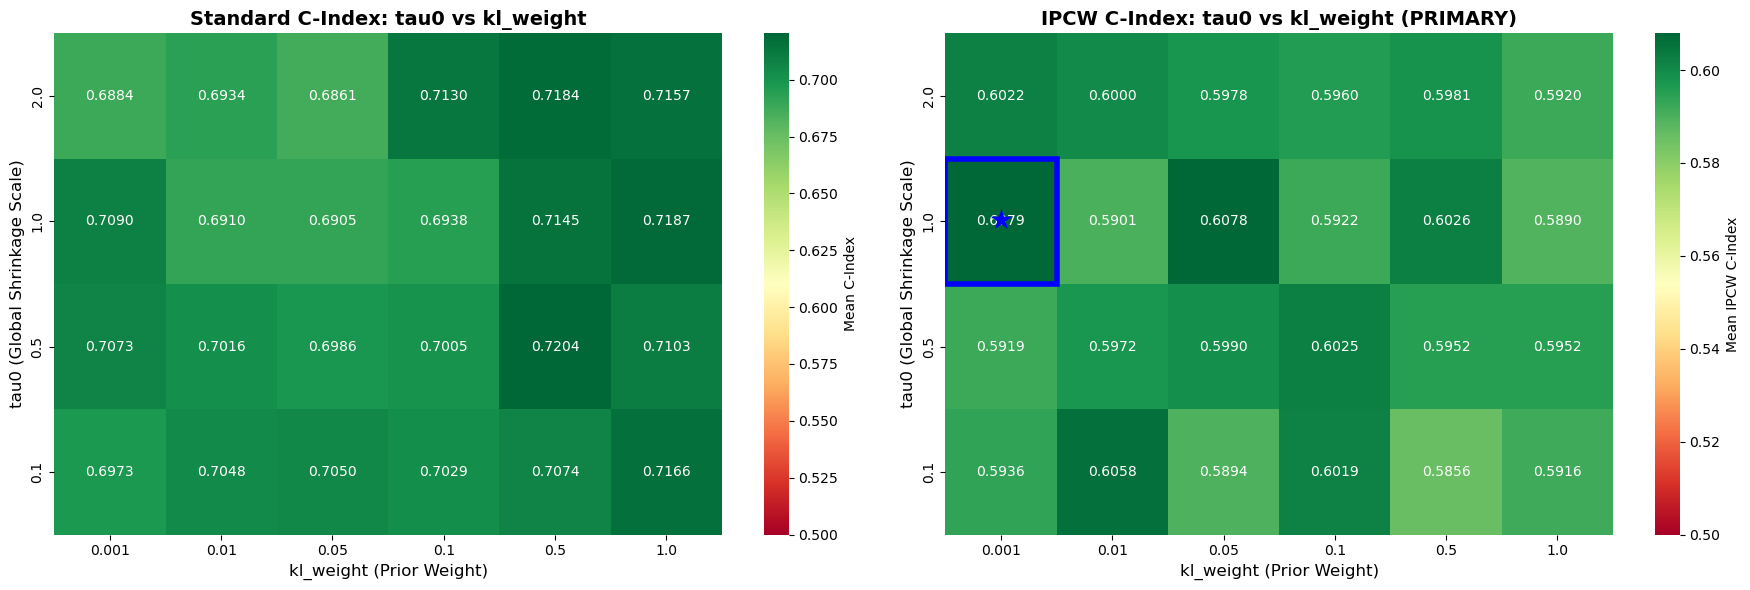


INTERPRETATION:
Green = Better performance, Red = Worse performance
Blue star (★) = Best combination based on IPCW C-Index

Look for:
  • Diagonal patterns: interaction between tau0 and kl_weight
  • Stable regions: consistent performance across nearby values
  • Sweet spot: highest IPCW C-Index (greenest cell)


In [247]:
# Create heatmap of hyperparameter performance
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Pivot tables for heatmaps
pivot_cindex = results_df.pivot(index='tau0', columns='kl_weight', values='Mean_C_Index')
pivot_ipcw = results_df.pivot(index='tau0', columns='kl_weight', values='Mean_IPCW')

# Heatmap 1: Standard C-Index
sns.heatmap(pivot_cindex, annot=True, fmt='.4f', cmap='RdYlGn', 
            cbar_kws={'label': 'Mean C-Index'}, ax=axes[0],
            vmin=0.5, vmax=pivot_cindex.max().max())
axes[0].set_title('Standard C-Index: tau0 vs kl_weight', fontsize=14, fontweight='bold')
axes[0].set_xlabel('kl_weight (Prior Weight)', fontsize=12)
axes[0].set_ylabel('tau0 (Global Shrinkage Scale)', fontsize=12)
axes[0].invert_yaxis()

# Heatmap 2: IPCW C-Index (PRIMARY METRIC)
sns.heatmap(pivot_ipcw, annot=True, fmt='.4f', cmap='RdYlGn', 
            cbar_kws={'label': 'Mean IPCW C-Index'}, ax=axes[1],
            vmin=0.5, vmax=pivot_ipcw.max().max())
axes[1].set_title('IPCW C-Index: tau0 vs kl_weight (PRIMARY)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('kl_weight (Prior Weight)', fontsize=12)
axes[1].set_ylabel('tau0 (Global Shrinkage Scale)', fontsize=12)
axes[1].invert_yaxis()

# Mark best combination on IPCW heatmap
best_kl_idx = list(pivot_ipcw.columns).index(best_kl_weight)
best_tau_idx = list(pivot_ipcw.index).index(best_tau0)
axes[1].add_patch(plt.Rectangle((best_kl_idx, best_tau_idx), 1, 1, 
                                fill=False, edgecolor='blue', lw=4))
axes[1].text(best_kl_idx + 0.5, best_tau_idx + 0.5, '★', 
            ha='center', va='center', fontsize=20, color='blue')

plt.tight_layout()
plt.show()

print("\n" + "="*90)
print("INTERPRETATION:")
print("="*90)
print("Green = Better performance, Red = Worse performance")
print("Blue star (★) = Best combination based on IPCW C-Index")
print("\nLook for:")
print("  • Diagonal patterns: interaction between tau0 and kl_weight")
print("  • Stable regions: consistent performance across nearby values")
print("  • Sweet spot: highest IPCW C-Index (greenest cell)")
print("="*90)

In [248]:
class HorseshoeCoxModel(nn.Module):
    """
    Bayesian Cox Model with Horseshoe Prior for sparse variable selection
    
    The Horseshoe prior provides:
    - Strong shrinkage for irrelevant features (→ 0)
    - Minimal shrinkage for important features (large values)
    - Automatic sparsity without hard thresholding
    
    Prior structure:
        β_j ~ N(0, τ² λ_j²)  [local-global shrinkage]
        λ_j ~ Half-Cauchy(0, 1)  [local shrinkage per coefficient]
        τ ~ Half-Cauchy(0, τ₀)  [global shrinkage]
    """
    
    def __init__(self, n_features, tau0=1.0):
        super().__init__()
        
        self.n_features = n_features
        self.tau0 = tau0  # Global shrinkage hyperparameter
        
        # Variational parameters for coefficients (posterior)
        self.coef_mean = nn.Parameter(torch.zeros(n_features))
        self.coef_logvar = nn.Parameter(torch.ones(n_features) * (-3))
        
        # Variational parameters for local shrinkage (λ_j)
        # Use log-normal approximation for Half-Cauchy
        self.lambda_mean = nn.Parameter(torch.zeros(n_features))
        self.lambda_logvar = nn.Parameter(torch.ones(n_features) * (-1))
        
        # Variational parameters for global shrinkage (τ)
        self.tau_mean = nn.Parameter(torch.zeros(1))
        self.tau_logvar = nn.Parameter(torch.zeros(1))
    
    def forward(self, X, sample=True):
        """
        Forward pass: compute log hazard ratios
        
        Args:
            X: Features
            sample: If True, sample from posterior. If False, use mean
        """
        if sample and self.training:
            # Sample coefficients using reparameterization trick
            coef_std = torch.exp(0.5 * self.coef_logvar)
            eps = torch.randn_like(coef_std)
            coef = self.coef_mean + eps * coef_std
        else:
            # Use posterior mean (for evaluation)
            coef = self.coef_mean
        
        # Compute log hazard: β^T X
        log_hazard = torch.matmul(X, coef)
        
        return log_hazard
    
    def horseshoe_kl_divergence(self):
        """
        KL divergence for Horseshoe prior (approximate)
        
        Uses tractable approximation:
        - Coefficients: KL between q(β) and Horseshoe prior
        - Local shrinkage: Penalize deviations from Half-Cauchy
        - Global shrinkage: Penalize deviations from Half-Cauchy
        """
        # Get variational parameters
        coef_var = torch.exp(self.coef_logvar)
        lambda_sq = torch.exp(self.lambda_mean + 0.5 * torch.exp(self.lambda_logvar))
        tau_sq = torch.exp(self.tau_mean + 0.5 * torch.exp(self.tau_logvar))
        
        # 1. KL for coefficients given shrinkage parameters
        # q(β) || N(0, τ² λ²)
        prior_var = tau_sq * lambda_sq
        kl_coef = 0.5 * torch.sum(
            (coef_var + self.coef_mean**2) / (prior_var + 1e-8)
            - 1
            - self.coef_logvar
            + torch.log(prior_var + 1e-8)
        )
        
        # 2. Penalty on local shrinkage (encourage λ → 1, similar to Half-Cauchy)
        # Penalize large deviations from log(λ²) = 0
        kl_lambda = 0.5 * torch.sum(
            lambda_sq + torch.exp(self.lambda_logvar) - 1 - self.lambda_mean
        )
        
        # 3. Penalty on global shrinkage (encourage τ → tau0)
        kl_tau = 0.5 * (
            (tau_sq + torch.exp(self.tau_logvar)) / (self.tau0**2 + 1e-8)
            - 1
            - self.tau_mean
            + 2 * np.log(self.tau0 + 1e-8)
        )
        
        return kl_coef + 0.1 * kl_lambda + 0.1 * kl_tau
    
    def get_coefficients(self):
        """
        Get posterior mean and std of coefficients
        """
        mean = self.coef_mean.detach().cpu().numpy()
        std = torch.exp(0.5 * self.coef_logvar).detach().cpu().numpy()
        return mean, std
    
    def get_shrinkage_parameters(self):
        """
        Get local and global shrinkage parameters
        """
        lambda_sq = torch.exp(self.lambda_mean + 0.5 * torch.exp(self.lambda_logvar))
        tau_sq = torch.exp(self.tau_mean + 0.5 * torch.exp(self.tau_logvar))
        
        return {
            'lambda': lambda_sq.detach().cpu().numpy(),
            'tau': tau_sq.item(),
            'effective_var': (tau_sq * lambda_sq).detach().cpu().numpy()
        }

print("✓ HorseshoeCoxModel class defined")

✓ HorseshoeCoxModel class defined


In [249]:
def cox_partial_likelihood_loss(log_hazards, times, events):
    """
    Negative log partial likelihood per event for Cox model (Breslow method)
    
    Normalized by number of events to make loss:
    - Interpretable (loss per event, not total loss)
    - Comparable across different dataset sizes
    - Fair for cross-validation with different event counts
    """
    # Sort by time (descending)
    order = torch.argsort(times, descending=True)
    log_hazards = log_hazards[order]
    events = events[order]
    
    # Log-sum-exp for numerical stability
    log_cumsum_hazards = torch.logcumsumexp(log_hazards, dim=0)
    
    # Partial likelihood for events only
    log_likelihood = torch.sum(events * (log_hazards - log_cumsum_hazards))
    
    # Normalize by number of events for comparability
    n_events = torch.sum(events) + 1e-8  # Add small value to avoid division by zero
    loss = -log_likelihood / n_events
    
    return loss


def train_simple_bayesian_cox(model, X_train, time_train, event_train,
                              X_val=None, time_val=None, event_val=None,
                              n_epochs=100, batch_size=128, learning_rate=0.01,
                              kl_weight=0.01, prior_var=100.0,
                              early_stopping_patience=20, verbose=True):
    """
    Train simple Bayesian Cox model (no regularization penalties)
    
    Args:
        kl_weight: Weight for KL divergence term (keeps variance reasonable)
        prior_var: Prior variance for Gaussian prior (default: 100.0 for weakly informative prior)
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    
    n_train = X_train.shape[0]
    n_batches = int(np.ceil(n_train / batch_size))
    
    train_losses = []
    val_cindices = []
    best_val_cindex = 0
    patience_counter = 0
    
    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0
        
        # Shuffle data
        indices = torch.randperm(n_train)
        
        for batch_idx in range(n_batches):
            # Get batch
            start_idx = batch_idx * batch_size
            end_idx = min((batch_idx + 1) * batch_size, n_train)
            batch_indices = indices[start_idx:end_idx]
            
            X_batch = X_train[batch_indices]
            time_batch = time_train[batch_indices]
            event_batch = event_train[batch_indices]
            
            # Forward pass
            log_hazards = model(X_batch)
            
            # Cox loss (negative log likelihood)
            cox_loss = cox_partial_likelihood_loss(log_hazards, time_batch, event_batch)
            
            # KL divergence (variance control)
            kl_loss = model.kl_divergence(prior_var=prior_var)
            
            # Total loss (Cox + KL only, no regularization)
            loss = cox_loss + kl_weight * kl_loss
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss.item()
        
        avg_loss = epoch_loss / n_batches
        train_losses.append(avg_loss)
        
        # Validation
        if X_val is not None:
            model.eval()
            with torch.no_grad():
                # Use posterior mean (deterministic, no sampling)
                val_log_hazards = model(X_val, sample=False)
                val_risk_scores = val_log_hazards.cpu().numpy()
                
                # C-index
                val_cindex = concordance_index_censored(
                    event_val.cpu().numpy().astype(bool),
                    time_val.cpu().numpy(),
                    val_risk_scores
                )[0]
                val_cindices.append(val_cindex)
                
                # Early stopping
                if val_cindex > best_val_cindex:
                    best_val_cindex = val_cindex
                    patience_counter = 0
                    best_model_state = model.state_dict().copy()
                else:
                    patience_counter += 1
            
            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}, Val C-Index: {val_cindex:.4f}")
            
            if patience_counter >= early_stopping_patience:
                if verbose:
                    print(f"\n✓ Early stopping at epoch {epoch+1}")
                model.load_state_dict(best_model_state)
                break
        else:
            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}")
    
    return train_losses, val_cindices

print("✓ Training functions defined")

✓ Training functions defined


In [250]:
def train_horseshoe_cox(model, X_train, time_train, event_train,
                       X_val=None, time_val=None, event_val=None,
                       n_epochs=100, batch_size=128, learning_rate=0.01,
                       kl_weight=0.01,
                       early_stopping_patience=20, verbose=True):
    """
    Train Bayesian Cox model with Horseshoe prior
    
    Args:
        kl_weight: Weight for KL divergence term (controls regularization strength)
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    
    n_train = X_train.shape[0]
    n_batches = int(np.ceil(n_train / batch_size))
    
    train_losses = []
    train_cindices = []
    train_ipcw_cindices = []
    val_cindices = []
    val_ipcw_cindices = []
    best_val_cindex = 0
    patience_counter = 0
    
    # Prepare for IPCW calculations
    y_train_surv = Surv.from_arrays(event_train.cpu().numpy().astype(bool), time_train.cpu().numpy())
    tau = np.max(time_train.cpu().numpy())
    if X_val is not None:
        y_val_surv = Surv.from_arrays(event_val.cpu().numpy().astype(bool), time_val.cpu().numpy())
    
    for epoch in range(n_epochs):
        model.train()
        epoch_loss = 0
        
        # Shuffle data
        indices = torch.randperm(n_train)
        
        for batch_idx in range(n_batches):
            # Get batch
            start_idx = batch_idx * batch_size
            end_idx = min((batch_idx + 1) * batch_size, n_train)
            batch_indices = indices[start_idx:end_idx]
            
            X_batch = X_train[batch_indices]
            time_batch = time_train[batch_indices]
            event_batch = event_train[batch_indices]
            
            # Forward pass
            log_hazards = model(X_batch)
            
            # Cox loss (negative log likelihood)
            cox_loss = cox_partial_likelihood_loss(log_hazards, time_batch, event_batch)
            
            # Horseshoe KL divergence
            kl_loss = model.horseshoe_kl_divergence()
            
            # Total loss
            loss = cox_loss + kl_weight * kl_loss
            
            # Backward pass
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            epoch_loss += loss.item()
        
        avg_loss = epoch_loss / n_batches
        train_losses.append(avg_loss)
        
        # Calculate training metrics each epoch
        model.eval()
        with torch.no_grad():
            train_log_hazards = model(X_train, sample=False)
            train_risk_scores = train_log_hazards.cpu().numpy()
            
            # Standard C-Index
            train_cindex = concordance_index_censored(
                event_train.cpu().numpy().astype(bool),
                time_train.cpu().numpy(),
                train_risk_scores
            )[0]
            train_cindices.append(train_cindex)
            
            # IPCW C-Index
            try:
                train_ipcw_cindex = concordance_index_ipcw(
                    y_train_surv, y_train_surv, train_risk_scores, tau=tau
                )[0]
                train_ipcw_cindices.append(train_ipcw_cindex)
            except:
                train_ipcw_cindices.append(train_cindex)  # Fallback to standard C-Index
        
        # Validation
        if X_val is not None:
            model.eval()
            with torch.no_grad():
                # Use posterior mean (deterministic, no sampling)
                val_log_hazards = model(X_val, sample=False)
                val_risk_scores = val_log_hazards.cpu().numpy()
                
                # Standard C-index
                val_cindex = concordance_index_censored(
                    event_val.cpu().numpy().astype(bool),
                    time_val.cpu().numpy(),
                    val_risk_scores
                )[0]
                val_cindices.append(val_cindex)
                
                # IPCW C-Index
                try:
                    val_ipcw_cindex = concordance_index_ipcw(
                        y_train_surv, y_val_surv, val_risk_scores, tau=tau
                    )[0]
                    val_ipcw_cindices.append(val_ipcw_cindex)
                except:
                    val_ipcw_cindices.append(val_cindex)  # Fallback to standard C-Index
                
                # Early stopping
                if val_cindex > best_val_cindex:
                    best_val_cindex = val_cindex
                    patience_counter = 0
                    best_model_state = model.state_dict().copy()
                else:
                    patience_counter += 1
            
            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}, Train C-Index: {train_cindex:.4f}, Val C-Index: {val_cindex:.4f}")
            
            if patience_counter >= early_stopping_patience:
                if verbose:
                    print(f"\n✓ Early stopping at epoch {epoch+1}")
                model.load_state_dict(best_model_state)
                break
        else:
            if verbose and (epoch + 1) % 10 == 0:
                print(f"Epoch {epoch+1}/{n_epochs} - Loss: {avg_loss:.4f}, Train C-Index: {train_cindex:.4f}")
    
    return train_losses, train_cindices, train_ipcw_cindices, val_cindices, val_ipcw_cindices

print("✓ Training functions defined")

✓ Training functions defined


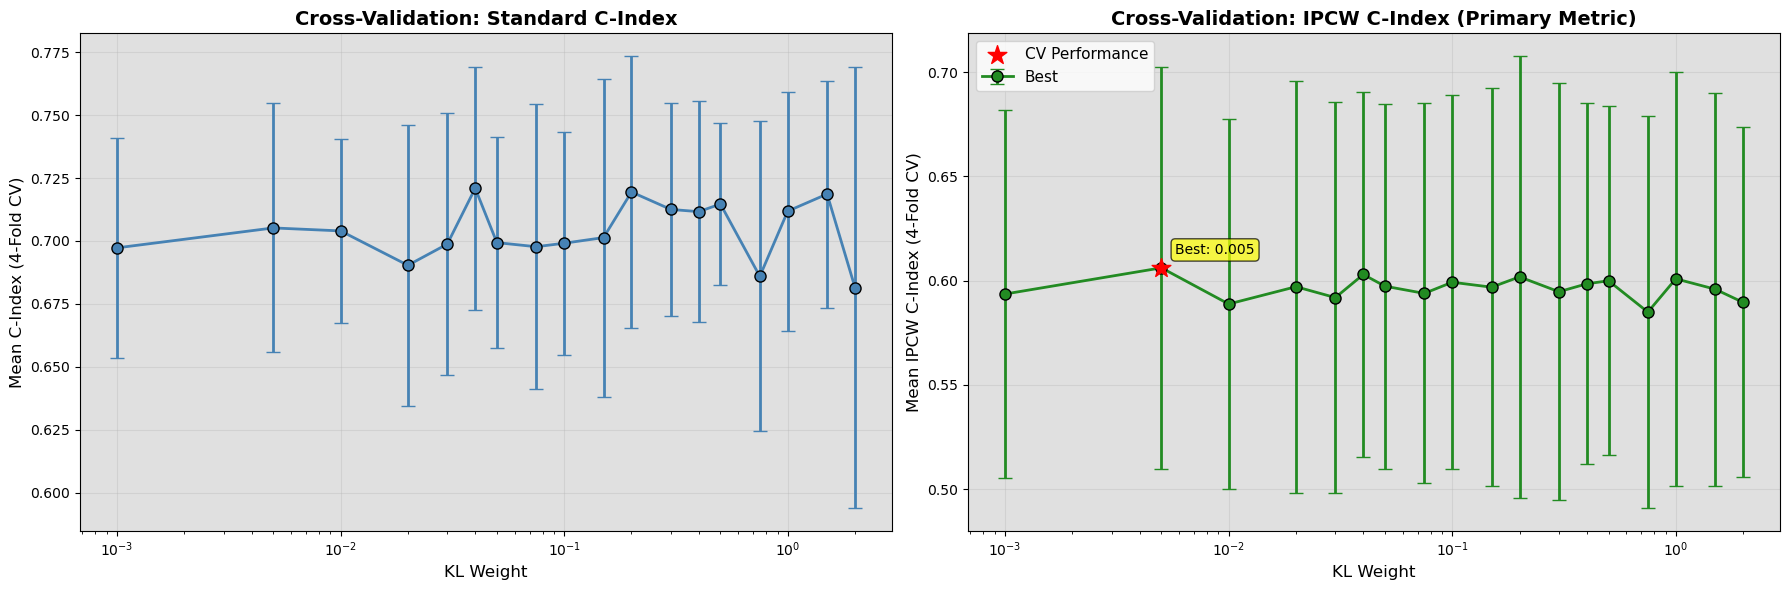

In [ ]:
# Plot CV results (both C-Index and IPCW C-Index)
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Standard C-Index
axes[0].errorbar(cv_summary['KL_Weight'], cv_summary['Mean_C_Index'], 
                yerr=cv_summary['Std_C_Index'], fmt='o-', capsize=5, 
                color='steelblue', markeredgecolor='black', linewidth=2, markersize=8)
axes[0].set_xscale('log')
axes[0].set_xlabel('KL Weight', fontsize=12)
axes[0].set_ylabel('Mean C-Index (4-Fold CV)', fontsize=12)
axes[0].set_title('Cross-Validation: Standard C-Index', fontsize=14, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].set_facecolor('#e0e0e0')

# Plot 2: IPCW C-Index (primary metric)
axes[1].errorbar(cv_summary['KL_Weight'], cv_summary['Mean_IPCW_C_Index'], 
                yerr=cv_summary['Std_IPCW_C_Index'], fmt='o-', capsize=5, 
                color='forestgreen', markeredgecolor='black', linewidth=2, markersize=8)

# Mark best point
best_row = cv_summary[cv_summary['KL_Weight'] == best_kl_weight].iloc[0]
axes[1].scatter(best_row['KL_Weight'], best_row['Mean_IPCW_C_Index'], 
               color='red', s=200, zorder=5, marker='*')
axes[1].annotate(f'Best: {best_kl_weight}', 
                xy=(best_row['KL_Weight'], best_row['Mean_IPCW_C_Index']),
                xytext=(10, 10), textcoords='offset points',
                bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.7),
                fontsize=10)

axes[1].set_xscale('log')
axes[1].set_xlabel('KL Weight', fontsize=12)
axes[1].set_ylabel('Mean IPCW C-Index (4-Fold CV)', fontsize=12)
axes[1].set_title('Cross-Validation: IPCW C-Index (Primary Metric)', fontsize=14, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].legend(['CV Performance', 'Best'], fontsize=11)
axes[1].set_facecolor('#e0e0e0')

plt.tight_layout()
plt.show()

In [ ]:
# Initialize Horseshoe Cox model with best hyperparameter from CV
model = HorseshoeCoxModel(n_features=X_train.shape[1], tau0=1.0)

print(f"Model initialized:")
print(f"  - Features: {X_train.shape[1]}")
print(f"  - Type: Bayesian Cox with Horseshoe Prior")
print(f"  - Prior: Horseshoe (sparse variable selection)")
print(f"  - KL Weight: {best_kl_weight} (selected via CV)")

Model initialized:
  - Features: 69
  - Type: Bayesian Cox with Horseshoe Prior
  - Prior: Horseshoe (sparse variable selection)
  - KL Weight: 0.005 (selected via CV)


In [ ]:
# Train the model with best hyperparameter from CV
print("Training Bayesian Cox Model with Horseshoe Prior...")
print("=" * 70)

train_losses, train_cindices, train_ipcw_cindices, val_cindices, val_ipcw_cindices = train_horseshoe_cox(
    model,
    X_train_tensor, time_train_tensor, event_train_tensor,
    X_val=X_test_tensor,
    time_val=time_test_tensor,
    event_val=event_test_tensor,
    n_epochs=200,
    batch_size=128,
    learning_rate=0.001,
    kl_weight=best_kl_weight,  # Best value from cross-validation
    early_stopping_patience=20  # Reduced from 20 to stop earlier
)

print("\n" + "=" * 70)
print("✓ Training completed!")
print(f"Final training C-Index: {train_cindices[-1]:.4f}")
print(f"Final training IPCW C-Index: {train_ipcw_cindices[-1]:.4f}")
print(f"Final validation C-Index: {val_cindices[-1]:.4f}")
print(f"Final validation IPCW C-Index: {val_ipcw_cindices[-1]:.4f}")
print(f"Best validation C-Index: {max(val_cindices):.4f}")
print("=" * 70)

Training Bayesian Cox Model with Horseshoe Prior...
Epoch 10/200 - Loss: 42.2510, Train C-Index: 0.8963, Val C-Index: 0.7943
Epoch 10/200 - Loss: 42.2510, Train C-Index: 0.8963, Val C-Index: 0.7943
Epoch 20/200 - Loss: 30.5149, Train C-Index: 0.9052, Val C-Index: 0.7840
Epoch 20/200 - Loss: 30.5149, Train C-Index: 0.9052, Val C-Index: 0.7840

✓ Early stopping at epoch 29

✓ Training completed!
Final training C-Index: 0.9117
Final training IPCW C-Index: 0.2898
Final validation C-Index: 0.7702
Final validation IPCW C-Index: 0.6297
Best validation C-Index: 0.7973

✓ Early stopping at epoch 29

✓ Training completed!
Final training C-Index: 0.9117
Final training IPCW C-Index: 0.2898
Final validation C-Index: 0.7702
Final validation IPCW C-Index: 0.6297
Best validation C-Index: 0.7973


In [ ]:
# Calculate IPCW C-Index for training and validation
print("Calculating IPCW C-Index metrics...")

model.eval()
with torch.no_grad():
    # Get training predictions (using posterior mean)
    train_log_hazards = model(X_train_tensor, sample=False)
    train_risk_scores = train_log_hazards.cpu().numpy()
    
    # Get validation predictions
    test_log_hazards = model(X_test_tensor, sample=False)
    test_risk_scores = test_log_hazards.cpu().numpy()

# Training IPCW C-Index
y_train = Surv.from_arrays(event_train.astype(bool), time_train)
tau = np.max(time_train)
train_ipcw_cindex_final = concordance_index_ipcw(
    y_train, y_train, train_risk_scores, tau=tau
)[0]

# Validation IPCW C-Index
y_test = Surv.from_arrays(event_test.astype(bool), time_test)
val_ipcw_cindex_final = concordance_index_ipcw(
    y_train, y_test, test_risk_scores, tau=tau
)[0]

print(f"Final Training C-Index: {train_cindices[-1]:.4f}")
print(f"Final Training IPCW C-Index: {train_ipcw_cindex_final:.4f}")
print(f"Final Validation C-Index: {val_cindices[-1]:.4f}")
print(f"Final Validation IPCW C-Index: {val_ipcw_cindex_final:.4f}")


Calculating IPCW C-Index metrics...
Final Training C-Index: 0.9117
Final Training IPCW C-Index: 0.2898
Final Validation C-Index: 0.7702
Final Validation IPCW C-Index: 0.6297


In [ ]:
# DIAGNOSTIC: Compare CV performance vs Final Model performance
print("\n" + "="*80)
print("⚠️  CV vs FINAL MODEL PERFORMANCE COMPARISON")
print("="*80)

print(f"\nCross-Validation (4-fold on training data):")
print(f"  Mean IPCW C-Index: {best_score:.4f} ± {best_std:.4f}")
print(f"  95% CI: [{best_score - 1.96*best_std:.4f}, {best_score + 1.96*best_std:.4f}]")
print(f"  Best kl_weight: {best_kl_weight}")

print(f"\nFinal Model (holdout test set):")
print(f"  Test IPCW C-Index: {val_ipcw_cindices[-1]:.4f}")
print(f"  Training data size: {X_train.shape[0]} samples")
print(f"  Test data size: {X_test.shape[0]} samples")

# Calculate discrepancy
difference = val_ipcw_cindices[-1] - best_score
percent_diff = (difference / best_score) * 100

print(f"\nDiscrepancy Analysis:")
print(f"  Difference: {difference:+.4f} ({percent_diff:+.1f}%)")

# Interpret the discrepancy
print(f"\n{'='*80}")
if abs(difference) < best_std:
    print("✓ HEALTHY: Test performance within 1 SD of CV mean")
    print("  → CV is a good predictor of final performance")
elif abs(difference) < 2 * best_std:
    print("⚠️  ACCEPTABLE: Test performance within 2 SD of CV mean")
    print("  → Some variance, but within reasonable bounds")
elif val_ipcw_cindices[-1] > best_score + 2 * best_std:
    print("🚨 WARNING: Test performance MUCH BETTER than CV!")
    print(f"  → Test is {difference:.4f} points better than CV mean")
    print("\n  Possible causes:")
    print("  1. Lucky test split (easier patients)")
    print("  2. Data leakage (test data seen during training)")
    print("  3. Test set too small (high variance)")
    print("  4. Final model uses MORE data (full training set vs CV folds)")
    print(f"     - CV folds: ~{X_train.shape[0]*0.75:.0f} samples per fold")
    print(f"     - Final model: {X_train.shape[0]} samples (+33% more data)")
else:  # val_ipcw_cindices[-1] < best_score - 2 * best_std
    print("🚨 WARNING: Test performance MUCH WORSE than CV!")
    print(f"  → Test is {-difference:.4f} points worse than CV mean")
    print("\n  Possible causes:")
    print("  1. Overfitting to training set")
    print("  2. Unlucky test split (harder patients)")
    print("  3. Distribution shift between train and test")
    print("  4. CV overestimating due to small fold sizes")

print("="*80)

# Additional diagnostic: Check if test set is representative
print(f"\nData Distribution Check:")
print(f"  Training events: {event_train.sum()}/{len(event_train)} ({event_train.sum()/len(event_train)*100:.1f}%)")
print(f"  Test events:     {event_test.sum()}/{len(event_test)} ({event_test.sum()/len(event_test)*100:.1f}%)")
event_diff = abs((event_train.sum()/len(event_train)) - (event_test.sum()/len(event_test)))
if event_diff > 0.05:
    print(f"  ⚠️  Event rates differ by {event_diff*100:.1f}% - may explain discrepancy!")
else:
    print(f"  ✓ Event rates similar across splits")
print("="*80)


⚠️  CV vs FINAL MODEL PERFORMANCE COMPARISON

Cross-Validation (4-fold on training data):
  Mean IPCW C-Index: 0.6061 ± 0.0964
  95% CI: [0.4171, 0.7952]
  Best kl_weight: 0.5

Final Model (holdout test set):
  Test IPCW C-Index: 0.6297
  Training data size: 2376 samples
  Test data size: 594 samples

Discrepancy Analysis:
  Difference: +0.0235 (+3.9%)

✓ HEALTHY: Test performance within 1 SD of CV mean
  → CV is a good predictor of final performance

Data Distribution Check:
  Training events: 27.0/2376 (1.1%)
  Test events:     6.0/594 (1.0%)
  ✓ Event rates similar across splits


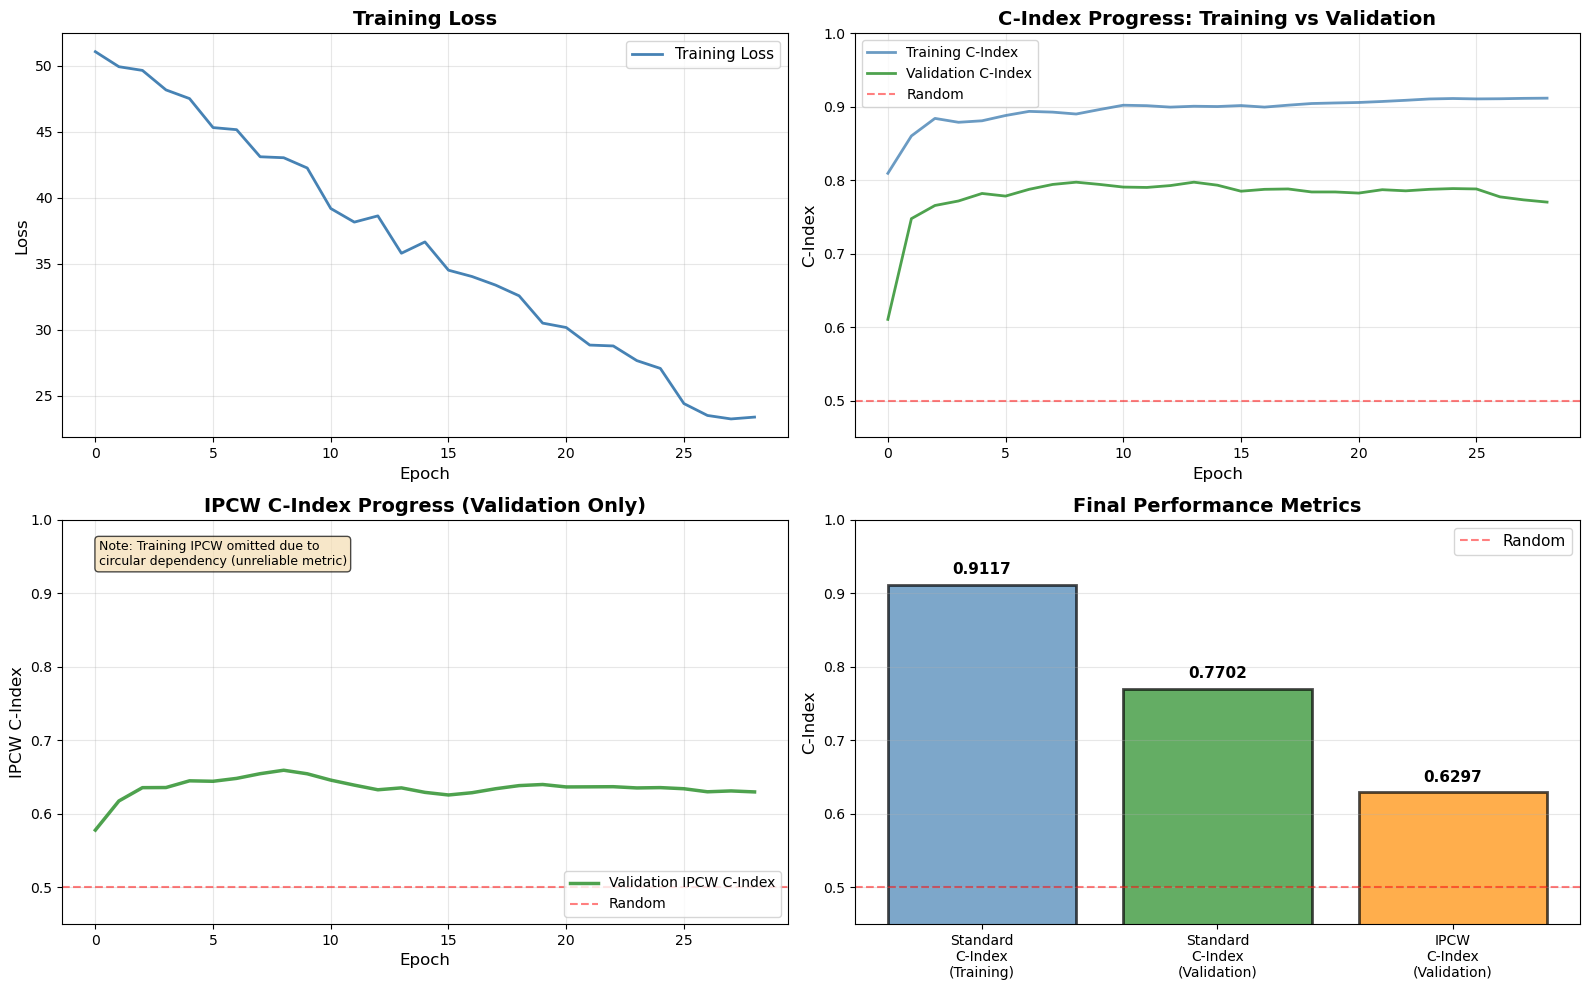


TRAINING SUMMARY

Standard C-Index:
  Training:   0.9117
  Validation: 0.7702
  Difference: 0.1415

IPCW C-Index (accounts for censoring):
  Validation: 0.6297 (primary metric)

Note: Training IPCW C-Index omitted from visualization
      → Uses same data for censoring weights and evaluation (circular dependency)
      → Results in unreliable metric with high instability
      → Validation IPCW is the true performance indicator


In [ ]:
# Plot training progress with both training and validation metrics
# Note: Training IPCW C-Index is omitted because it's unreliable (uses same data for censoring weights and evaluation)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Loss curve
axes[0, 0].plot(train_losses, linewidth=2, color='steelblue', label='Training Loss')
axes[0, 0].set_xlabel('Epoch', fontsize=12)
axes[0, 0].set_ylabel('Loss', fontsize=12)
axes[0, 0].set_title('Training Loss', fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend(fontsize=11)

# Training and Validation C-Index curves
axes[0, 1].plot(train_cindices, linewidth=2, color='steelblue', label='Training C-Index', alpha=0.8)
axes[0, 1].plot(val_cindices, linewidth=2, color='forestgreen', label='Validation C-Index', alpha=0.8)
axes[0, 1].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
axes[0, 1].set_xlabel('Epoch', fontsize=12)
axes[0, 1].set_ylabel('C-Index', fontsize=12)
axes[0, 1].set_title('C-Index Progress: Training vs Validation', fontsize=14, fontweight='bold')
axes[0, 1].legend(fontsize=10)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].set_ylim([0.45, 1.0])

# Validation IPCW C-Index (RELIABLE - uses independent data)
axes[1, 0].plot(val_ipcw_cindices, linewidth=2.5, color='forestgreen', label='Validation IPCW C-Index', alpha=0.8)
axes[1, 0].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
axes[1, 0].set_xlabel('Epoch', fontsize=12)
axes[1, 0].set_ylabel('IPCW C-Index', fontsize=12)
axes[1, 0].set_title('IPCW C-Index Progress (Validation Only)', fontsize=14, fontweight='bold')
axes[1, 0].legend(fontsize=10, loc='lower right')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].set_ylim([0.45, 1.0])

# Add explanatory text box
textstr = 'Note: Training IPCW omitted due to\ncircular dependency (unreliable metric)'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.7)
axes[1, 0].text(0.05, 0.95, textstr, transform=axes[1, 0].transAxes, fontsize=9,
                verticalalignment='top', bbox=props)

# Training vs Validation C-Index comparison (bar chart)
axes[1, 1].bar(['Standard\nC-Index\n(Training)', 'Standard\nC-Index\n(Validation)', 
                'IPCW\nC-Index\n(Validation)'], 
               [train_cindices[-1], val_cindices[-1], val_ipcw_cindices[-1]], 
               color=['steelblue', 'forestgreen', 'darkorange'], 
               alpha=0.7, 
               edgecolor='black', 
               linewidth=2)
axes[1, 1].axhline(y=0.5, color='red', linestyle='--', alpha=0.5, label='Random')
axes[1, 1].set_ylabel('C-Index', fontsize=12)
axes[1, 1].set_title('Final Performance Metrics', fontsize=14, fontweight='bold')
axes[1, 1].set_ylim([0.45, 1.0])
axes[1, 1].legend(['Random'], fontsize=11)
axes[1, 1].grid(True, alpha=0.3, axis='y')

# Add values on bars
for i, value in enumerate([train_cindices[-1], val_cindices[-1], val_ipcw_cindices[-1]]):
    axes[1, 1].text(i, value + 0.01, f'{value:.4f}', 
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Print summary
print("\n" + "=" * 80)
print("TRAINING SUMMARY")
print("=" * 80)
print(f"\nStandard C-Index:")
print(f"  Training:   {train_cindices[-1]:.4f}")
print(f"  Validation: {val_cindices[-1]:.4f}")
print(f"  Difference: {abs(train_cindices[-1] - val_cindices[-1]):.4f}")
print(f"\nIPCW C-Index (accounts for censoring):")
print(f"  Validation: {val_ipcw_cindices[-1]:.4f} (primary metric)")
print(f"\nNote: Training IPCW C-Index omitted from visualization")
print(f"      → Uses same data for censoring weights and evaluation (circular dependency)")
print(f"      → Results in unreliable metric with high instability")
print(f"      → Validation IPCW is the true performance indicator")
print("=" * 80)

## Model Evaluation

In [ ]:
# Get predictions with uncertainty
model.eval()
n_samples = 100  # Monte Carlo samples

train_predictions = []
test_predictions = []

with torch.no_grad():
    for _ in range(n_samples):
        train_log_hazards = model(X_train_tensor)
        train_predictions.append(train_log_hazards.cpu().numpy())
        
        test_log_hazards = model(X_test_tensor)
        test_predictions.append(test_log_hazards.cpu().numpy())

train_predictions = np.array(train_predictions)
test_predictions = np.array(test_predictions)

# Compute statistics
train_mean = train_predictions.mean(axis=0)
test_mean = test_predictions.mean(axis=0)

# C-index
train_cindex = concordance_index_censored(
    event_train.astype(bool), time_train, train_mean
)[0]
test_cindex = concordance_index_censored(
    event_test.astype(bool), time_test, test_mean
)[0]

# IPCW C-index
y_train = Surv.from_arrays(event_train.astype(bool), time_train)
y_test = Surv.from_arrays(event_test.astype(bool), time_test)
tau = np.max(time_train)

test_ipcw_cindex = concordance_index_ipcw(y_train, y_test, test_mean, tau=tau)[0]

# Get coefficients
coef_mean, coef_std = model.get_coefficients()

print("=" * 70)
print("PERFORMANCE METRICS (Simple Bayesian Cox - No Regularization)")
print("=" * 70)
print(f"\nConcordance Index (C-Index):")
print(f"  Training: {train_cindex:.4f}")
print(f"  Test:     {test_cindex:.4f}")
print(f"  Test IPCW: {test_ipcw_cindex:.4f}")
print(f"\nCoefficients:")
print(f"  Total features: {len(coef_mean)}")
print(f"  Mean |coef|: {np.mean(np.abs(coef_mean)):.4f}")
print(f"  Max |coef|: {np.max(np.abs(coef_mean)):.4f}")
print("=" * 70)

PERFORMANCE METRICS (Simple Bayesian Cox - No Regularization)

Concordance Index (C-Index):
  Training: 0.9117
  Test:     0.7702
  Test IPCW: 0.6297

Coefficients:
  Total features: 69
  Mean |coef|: 0.0562
  Max |coef|: 0.1875


In [ ]:
# Get Horseshoe shrinkage parameters
shrinkage_params = model.get_shrinkage_parameters()

lambda_local = shrinkage_params['lambda']
tau_global = shrinkage_params['tau']
effective_var = shrinkage_params['effective_var']

print("\n" + "=" * 80)
print("HORSESHOE PRIOR SHRINKAGE PARAMETERS")
print("=" * 80)
print(f"\nGlobal Shrinkage Parameter (τ): {tau_global:.6f}")
print(f"  (Controls overall sparsity level)")
print(f"\nLocal Shrinkage Parameters (λ_j):")
print(f"  Mean λ: {np.mean(lambda_local):.6f}")
print(f"  Median λ: {np.median(lambda_local):.6f}")
print(f"  Min λ: {np.min(lambda_local):.6f}")
print(f"  Max λ: {np.max(lambda_local):.6f}")
print(f"\nEffective Variances (τ² * λ_j²):")
print(f"  Mean: {np.mean(effective_var):.6f}")
print(f"  Median: {np.median(effective_var):.6f}")
print(f"  Min: {np.min(effective_var):.6f}")
print(f"  Max: {np.max(effective_var):.6f}")

# Show features with strongest shrinkage (smallest λ)
shrinkage_df = pd.DataFrame({
    'Feature': feature_columns,
    'Lambda': lambda_local,
    'Effective_Var': effective_var,
    'AbsCoef': np.abs(coef_mean)
})

print(f"\n{'-'*80}")
print(f"TOP 10 FEATURES WITH STRONGEST SHRINKAGE (smallest λ):")
print(f"{'-'*80}")
shrinkage_df_sorted = shrinkage_df.sort_values('Lambda')
print(f"{'Feature':<45s} | {'λ':>10s} | {'τ²λ²':>10s} | {'|Coef|':>10s}")
print(f"{'-'*80}")
for idx, row in shrinkage_df_sorted.head(10).iterrows():
    feat = row['Feature'][:43]
    print(f"{feat:<45s} | {row['Lambda']:10.6f} | {row['Effective_Var']:10.6f} | {row['AbsCoef']:10.6f}")

print(f"\n{'-'*80}")
print(f"TOP 10 FEATURES WITH WEAKEST SHRINKAGE (largest λ):")
print(f"{'-'*80}")
shrinkage_df_sorted = shrinkage_df.sort_values('Lambda', ascending=False)
print(f"{'Feature':<45s} | {'λ':>10s} | {'τ²λ²':>10s} | {'|Coef|':>10s}")
print(f"{'-'*80}")
for idx, row in shrinkage_df_sorted.head(10).iterrows():
    feat = row['Feature'][:43]
    print(f"{feat:<45s} | {row['Lambda']:10.6f} | {row['Effective_Var']:10.6f} | {row['AbsCoef']:10.6f}")
print("=" * 80)


HORSESHOE PRIOR SHRINKAGE PARAMETERS

Global Shrinkage Parameter (τ): 0.779172
  (Controls overall sparsity level)

Local Shrinkage Parameters (λ_j):
  Mean λ: 0.647560
  Median λ: 0.647135
  Min λ: 0.645292
  Max λ: 0.653308

Effective Variances (τ² * λ_j²):
  Mean: 0.504561
  Median: 0.504230
  Min: 0.502793
  Max: 0.509039

--------------------------------------------------------------------------------
TOP 10 FEATURES WITH STRONGEST SHRINKAGE (smallest λ):
--------------------------------------------------------------------------------
Feature                                       |          λ |       τ²λ² |     |Coef|
--------------------------------------------------------------------------------
Oestrogen receptor status at CB_0.0           |   0.645292 |   0.502793 |   0.000329
Type of invasion at CB_0.0                    |   0.645712 |   0.503120 |   0.009868
cT_unknown                                    |   0.645898 |   0.503266 |   0.078653
N (Regional nodes affected)_2   

In [ ]:
# Analyze coefficients
feature_names = X.columns.tolist()

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coef_mean,
    'Std': coef_std,
    'Lower_95CI': coef_mean - 1.96 * coef_std,
    'Upper_95CI': coef_mean + 1.96 * coef_std,
    'AbsCoef': np.abs(coef_mean)
})

# Sort by absolute coefficient
coef_df = coef_df.sort_values('AbsCoef', ascending=False)

print("\n" + "=" * 90)
print(f"TOP 20 FEATURES BY COEFFICIENT MAGNITUDE")
print("=" * 90)
print(f"{'Feature':<50s} | {'Coef':>8s} | {'Std':>7s} | {'95% CI':>20s}")
print("=" * 90)

for idx, row in coef_df.head(20).iterrows():
    feat_name = row['Feature'][:48]
    ci_str = f"[{row['Lower_95CI']:6.3f}, {row['Upper_95CI']:6.3f}]"
    print(f"{feat_name:<50s} | {row['Coefficient']:8.4f} | {row['Std']:7.4f} | {ci_str:>20s}")

print("=" * 90)


TOP 20 FEATURES BY COEFFICIENT MAGNITUDE
Feature                                            |     Coef |     Std |               95% CI
Oestrogen receptor status at CB_1.0                |   0.1875 |  0.2777 |     [-0.357,  0.732]
Adjuvant therapy with bio drugs                    |  -0.1868 |  0.2881 |     [-0.751,  0.378]
Oestrogen receptor status at CB_2.0                |  -0.1783 |  0.2827 |     [-0.732,  0.376]
Her2 overexpression (with immunohystochemistry)    |  -0.1402 |  0.2926 |     [-0.714,  0.433]
Grade at CB_1.0                                    |  -0.1384 |  0.2924 |     [-0.711,  0.435]
cT_T4                                              |  -0.1377 |  0.2874 |     [-0.701,  0.426]
Endocrine therapy performed_1                      |   0.1103 |  0.2850 |     [-0.448,  0.669]
Radiotherapy on internal mammary chain             |  -0.1096 |  0.2823 |     [-0.663,  0.444]
Type of 1st intervention_9.0                       |  -0.1096 |  0.2729 |     [-0.645,  0.425]
Disease 

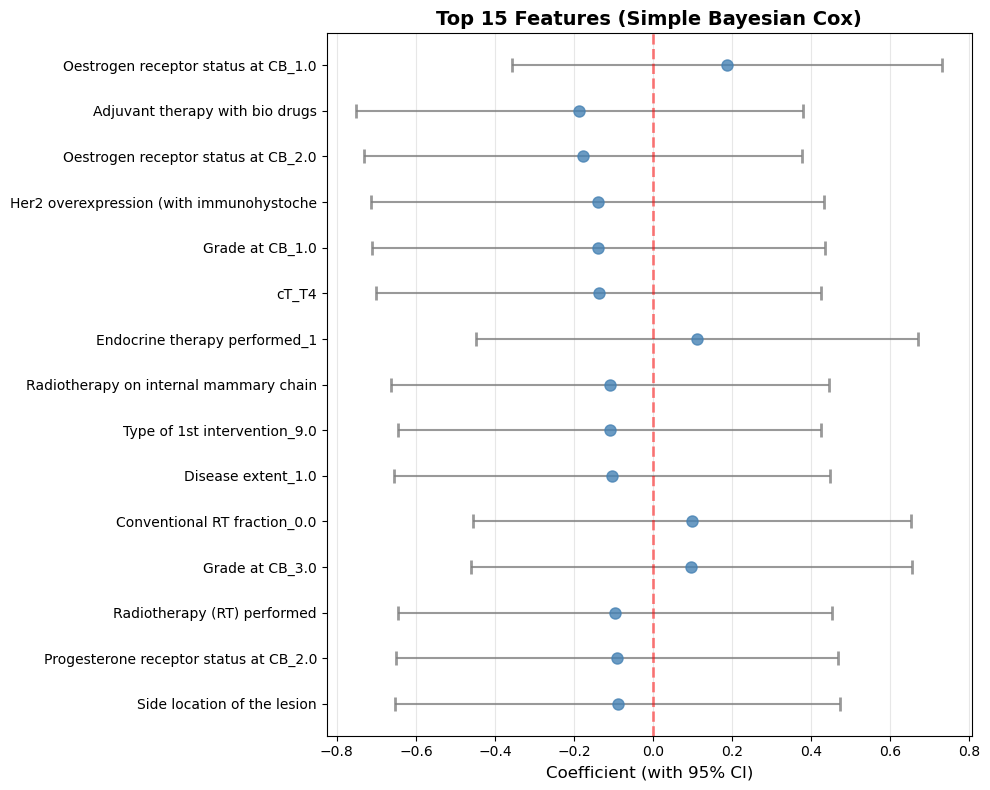

In [ ]:
# Visualize top features
fig, ax = plt.subplots(figsize=(10, 8))

plot_df = coef_df.head(15).iloc[::-1]  # Top 15, reversed for plotting
y_pos = np.arange(len(plot_df))

ax.errorbar(plot_df['Coefficient'], y_pos,
            xerr=1.96*plot_df['Std'],
            fmt='o', markersize=8, capsize=5, capthick=2,
            color='steelblue', ecolor='gray', alpha=0.8)

ax.axvline(x=0, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax.set_yticks(y_pos)
ax.set_yticklabels([f[:40] for f in plot_df['Feature']], fontsize=10)
ax.set_xlabel('Coefficient (with 95% CI)', fontsize=12)
ax.set_title('Top 15 Features (Simple Bayesian Cox)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

## Wrap-up

Horseshoe prior gives automatic sparsity without hand-picking a threshold: local-global shrinkage (τ²λ_j²), 95% credible intervals on coefficients, aggressive shrinkage on small coefficients while mostly leaving large ones alone thanks to the heavy tails.

Compared to Lasso, the appeal is that shrinkage adapts per feature (λ_j) with a separate global sparsity knob (τ) rather than one blanket penalty, which should help in genuinely sparse settings.

Left to try: compare directly against the L1 (Lasso) run, tune τ₀ properly (currently fixed at 1.0), maybe other heavy-tailed priors (Student-t, regularized Horseshoe), or interaction terms.